# v12 M: three interpretability tests of the self (no training)
Ideas from *Reading Model Minds*, applied to the translation models. Self, task and look-alike picks always have the **same number of neurons** (half of the smaller group, per layer).
- **Dial:** multiply the picked neurons' activity by 0, 0.5, 1.5, 2; hold them at their average; and push the decoder along the *confident minus unsure* direction with the **same push size for every group** (the fair version of the old steering test; the old unfair version is kept for comparison).
- **Broadcast:** nudge the model along one neuron's outgoing direction (same nudge size for all) and measure how much the final hidden state moves. Self neurons vs task neurons vs random directions.
- **Overlap:** find the self separately on each language's text; how much do the sets overlap compared with chance?

Models: distant 40, 41, 42 · related 13, 14, 15 · Hindi-only 45 (self found on Hindi) · mixed 45. Measured on the language each checkpoint was last trained on (Hindi for mixed).
Results: `analysis/v12/dial`, `broadcast`, `overlap` · progress: `tail -f logs/v12_M_mind.log`

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = os.environ.get("CML_GPU", "0"); LOG = "v12_M_mind"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
FILES, HF_REPO = [], None
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)
if not FILES:
    print("could not list the HF repo: only checkpoints already on this machine will be used")

def have(run, ph):
    return bool(glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"))

def get(run, phases):
    """download what is missing; returns the phases that are on this machine afterwards"""
    ok = []
    for ph in phases:
        if not have(run, ph):
            name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
            if name:
                try:
                    hf_hub_download(HF_REPO, name[0], local_dir="runs")
                except Exception as e:
                    print("download failed:", run, ph, type(e).__name__, e)
        if have(run, ph):
            ok.append(ph)
        else:
            print("not available (not here, not on HF):", run, ph)
    return ok

def run(langset, script, *cmd):
    """one call of a script; output shown here AND appended to logs/<LOG>.log (watch with: tail -f logs/<LOG>.log)"""
    env = {**os.environ, "CML_LANGSET": langset}; os.makedirs("logs", exist_ok=True)
    p = subprocess.Popen([sys.executable, "-u", script, "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    with open(f"logs/{LOG}.log", "a") as log:
        for line in p.stdout:
            print(line, end=""); log.write(line); log.flush()
    p.wait(); print("exit code", p.returncode)

def summary(script, part, out=None):
    cmd = [sys.executable, script, "--summarize", "--part", part] + (["--out", out] if out else [])
    r = subprocess.run(cmd, capture_output=True, text=True); print(r.stdout[-14000:]); print(r.stderr[-3000:])

def show(*paths):
    for f in paths:
        if os.path.exists(f): display(Image(f))

DIST, HIN, MIX, REL, REL1 = "v4b_continual_s0", "v4b_only_hi_s0", "v6b_mixed_s0", "v8_indic_continual_s0", "v8_indic_continual_s1"
print("GPU", GPU)

/venv/main/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


GPU 0


p041_zh.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p042_ar.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

distant phase 40 (last trained hi; measured on hi; self found on hi,zh,ar): untouched loss 1.083, entropy 1.714, top-1 75.7%, chrF 54.6


  entropy change (average of draws):
value              -2.0   -1.0    0.0    0.5    1.0    1.5    2.0
kind       group                                                 
gain       look     NaN    NaN  0.835  0.159    NaN  0.079  0.310
           self     NaN    NaN  1.434  0.225    NaN  0.135  0.485
           task     NaN    NaN  0.709  0.150    NaN  0.051  0.241
steer_same look  -0.300 -0.167    NaN    NaN  0.204    NaN  0.453
           self  -0.420 -0.237    NaN    NaN  0.297    NaN  0.667
           task  -0.228 -0.124    NaN    NaN  0.146    NaN  0.318
  hooks removed check: loss differs from untouched by 0.00000 (should be 0) | 40s


distant phase 41 (last trained zh; measured on zh; self found on hi,zh,ar): untouched loss 2.039, entropy 2.332, top-1 59.7%, chrF 27.4


  entropy change (average of draws):
value              -2.0   -1.0    0.0    0.5    1.0    1.5    2.0
kind       group                                                 
gain       look     NaN    NaN  0.585  0.118    NaN  0.069  0.264
           self     NaN    NaN  0.789  0.077    NaN  0.170  0.493
           task     NaN    NaN  0.608  0.145    NaN  0.037  0.198
steer_same look  -0.106 -0.072    NaN    NaN  0.114    NaN  0.280
           self  -0.113 -0.162    NaN    NaN  0.524    NaN  1.598
           task   0.264  0.112    NaN    NaN -0.078    NaN -0.122
  hooks removed check: loss differs from untouched by 0.00000 (should be 0) | 36s


... (16 outputs left out)

mixed phase 45 (last trained mix; measured on hi; self found on hi,zh,ar): untouched loss 1.232, entropy 1.889, top-1 73.2%, chrF 52.4


  entropy change (average of draws):
value              -2.0   -1.0    0.0    0.5    1.0    1.5    2.0
kind       group                                                 
gain       look     NaN    NaN  0.713  0.133    NaN  0.103  0.406
           self     NaN    NaN  1.036  0.190    NaN  0.096  0.392
           task     NaN    NaN  0.631  0.126    NaN  0.081  0.348
steer_same look  -0.121 -0.072    NaN    NaN  0.096    NaN  0.220
           self  -0.087 -0.055    NaN    NaN  0.082    NaN  0.193
           task   0.001 -0.010    NaN    NaN  0.031    NaN  0.085
  hooks removed check: loss differs from untouched by 0.00000 (should be 0) | 39s
done


exit code 0


lue            1.0
family  group       
distant look   0.272
        self   0.685
        task   0.276
hindi   look   0.541
        self   1.599
        task   0.529
mixed   look   0.558
        self   0.940
        task   0.562
related look   0.228
        self   0.840
        task   0.286
d_top1:
value             1.0
family  group        
distant look   -3.388
        self   -7.484
        task   -2.941
hindi   look   -4.474
        self  -13.549
        task   -4.088
mixed   look   -4.204
        self   -7.402
        task   -4.049
related look   -2.901
        self   -5.974
        task   -2.900
d_chrf:
value             1.0
family  group        
distant look   -3.245
        self  -10.560
        task   -2.581
hindi   look   -2.119
        self  -14.485
        task   -2.190
mixed   look   -1.675
        self   -7.125
        task   -1.317
related look   -0.278
        self   -6.937
        task   -0.313
self vs task: in how many comparisons does the self pick move the model MORE

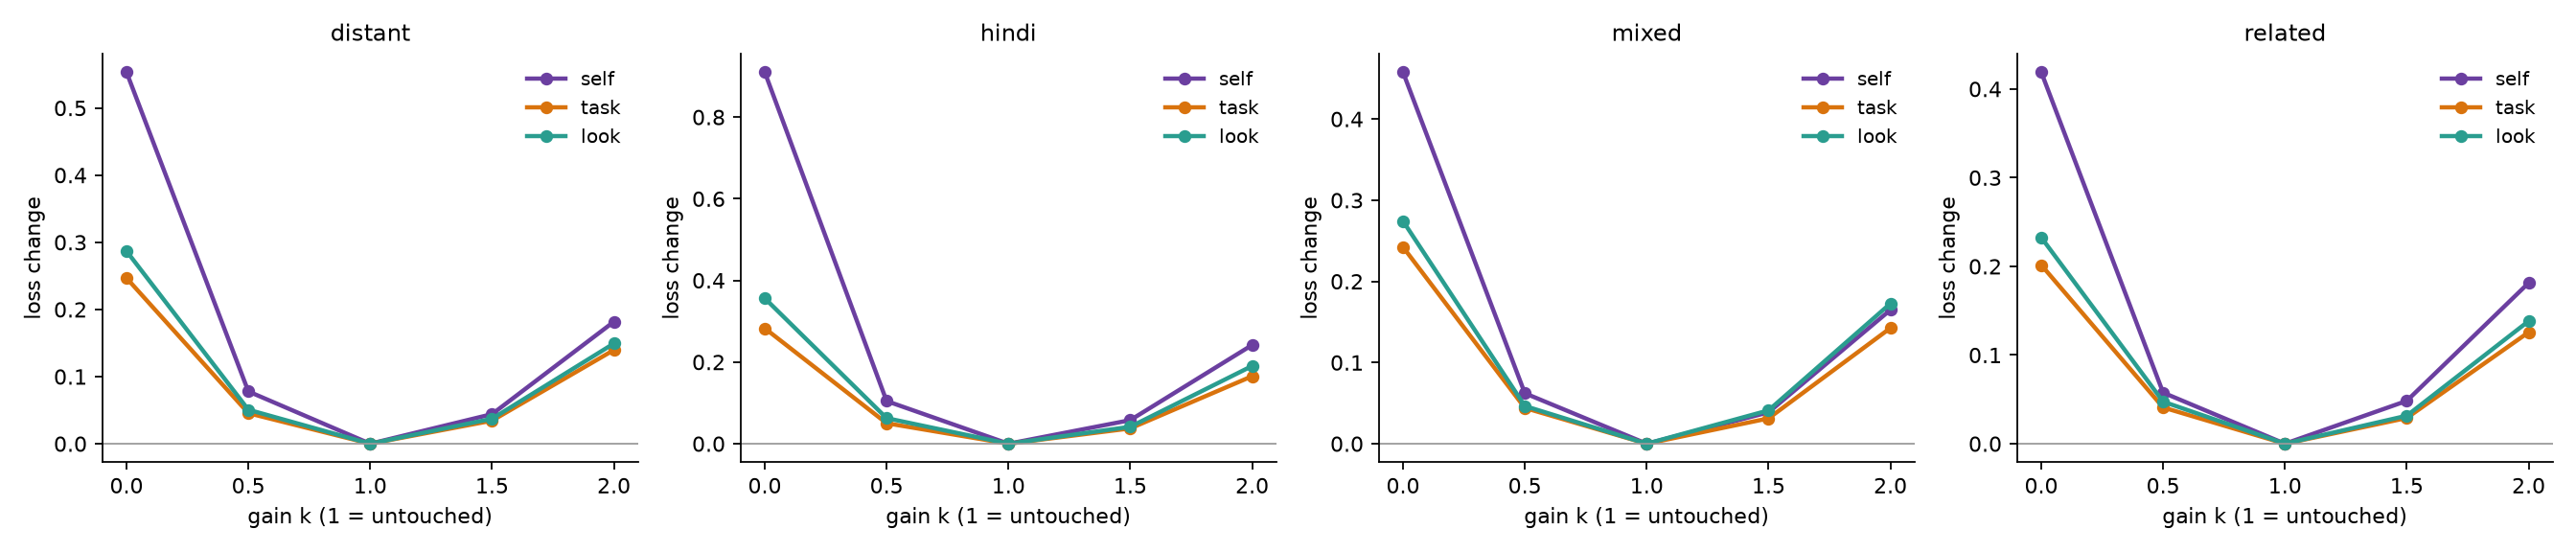

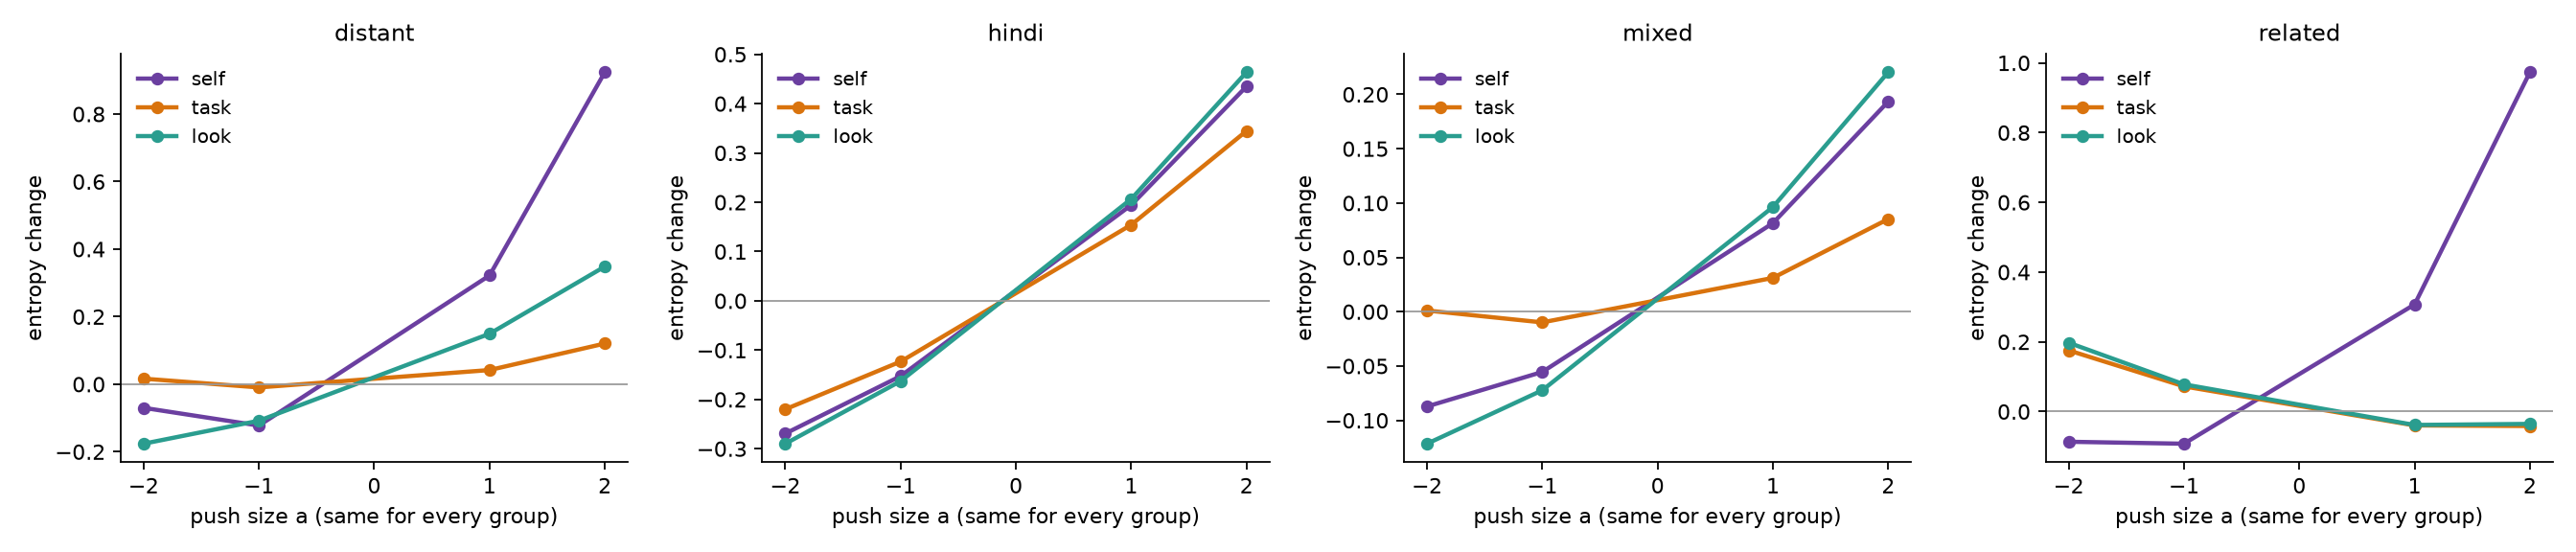

In [2]:
PLAN = [("distant", "distant", DIST, [40, 41, 42], None), ("indic", "related", REL, [13, 14, 15], None),
        ("distant", "hindi", HIN, [45], "hi"), ("distant", "mixed", MIX, [45], None)]
def go(part, plan):
    for langset, fam, r, phs, sl in plan:
        ok = get(r, phs)
        if ok:
            cmd = ["--part", part, "--family", fam, "--model", f"{fam}={r}:" + ",".join(str(p) for p in ok)]
            run(langset, "mind_v12.py", *(cmd + (["--self_langs", sl] if sl else [])))
go("dial", PLAN)
summary("mind_v12.py", "dial")
show("analysis/v12/dial/dial_gain_d_loss.png", "analysis/v12/dial/dial_steer_same_d_entropy.png")

In [3]:
go("broadcast", PLAN)
summary("mind_v12.py", "broadcast")

distant phase 40 (measured on hi): final-state movement per unit nudge
group  random   self   task
layer                      
enc0    6.121  6.934  6.730
enc1    4.944  5.691  5.977
enc2    4.032  4.490  4.626
enc3    3.622  4.060  4.469
dec0    5.972  6.774  6.162
dec1    4.636  4.991  4.944
dec2    3.488  3.511  3.471
dec3    2.897  2.762  2.837
  42s


distant phase 41 (measured on zh): final-state movement per unit nudge
group  random    self    task
layer                        
enc0    9.218  10.519  10.033
enc1    7.530   8.728   8.803
enc2    6.125   6.946   7.270
enc3    5.545   6.470   6.552
dec0    7.911   8.615   8.200
dec1    6.084   6.764   6.351
dec2    4.564   4.475   4.543
dec3    3.689   3.571   3.577
  39s


distant phase 42 (measured on ar): final-state movement per unit nudge
group  random   self   task
layer                      
enc0    6.243  7.138  6.860
enc1    5.089  5.947  6.124
enc2    4.157  4.809  4.876
enc3    3.764  4.289  4.590
dec0    5.884  6.370  6.278
dec1    4.673  5.152  5.014
dec2    3.551  3.518  3.578
dec3    2.921  2.828  2.769
  38s
done


exit code 0


related phase 13 (measured on hi): final-state movement per unit nudge
group  random   self   task
layer                      
enc0    4.009  4.512  4.462
enc1    3.354  3.751  4.043
enc2    2.926  3.408  3.487
enc3    2.662  3.042  3.206
dec0    5.239  5.701  5.262
dec1    3.866  4.138  3.931
dec2    2.948  2.973  2.964
dec3    2.418  2.333  2.351
  41s


related phase 14 (measured on gu): final-state movement per unit nudge
group  random   self   task
layer                      
enc0    4.811  5.365  5.332
enc1    3.977  4.517  4.602
enc2    3.452  3.785  4.080
enc3    3.099  3.666  3.814
dec0    5.835  6.260  5.944
dec1    4.330  4.771  4.426
dec2    3.296  3.288  3.332
dec3    2.665  2.548  2.579
  36s


... (3 outputs left out)

exit code 0


mixed phase 45 (measured on hi): final-state movement per unit nudge
group  random   self   task
layer                      
enc0    3.936  4.275  4.300
enc1    3.300  3.506  3.630
enc2    2.929  3.103  3.361
enc3    2.749  3.086  3.161
dec0    4.893  5.165  5.119
dec1    3.817  3.976  3.918
dec2    2.940  2.937  2.945
dec3    2.490  2.407  2.443
  42s
done


exit code 0


=== broadcast: how much the FINAL hidden state moves per unit of nudge along one direction at a layer (gain) ===
same nudge size for every direction; self / task = one neuron's outgoing weight direction; random = a random direction
group          random   self   task  self/task  self/random
family  layer                                              
distant dec0    6.589  7.253  6.880      1.054        1.101
        dec1    5.131  5.636  5.436      1.037        1.098
        dec2    3.868  3.834  3.864      0.992        0.991
        dec3    3.169  3.054  3.061      0.998        0.964
        enc0    7.194  8.197  7.874      1.041        1.139
        enc1    5.855  6.789  6.968      0.974        1.160
        enc2    4.771  5.415  5.591      0.969        1.135
        enc3    4.311  4.940  5.204      0.949        1.146
hindi   dec0    5.329  5.466  5.267      1.038        1.026
        dec1    3.800  4.107  3.898      1.053        1.081
        dec2    2.859  2.845  2.839      1.002  

In [4]:
go("overlap", [p for p in PLAN if p[1] != "hindi"])
summary("mind_v12.py", "overlap")

distant phase 40 (hi): overlap of the selfs found on each language
       jaccard  x_chance
layer                   
dec0     0.591     1.089
dec1     0.412     1.393
dec2     0.463     1.704
dec3     0.677     1.337
  12s


distant phase 41 (zh): overlap of the selfs found on each language
       jaccard  x_chance
layer                   
dec0     0.599     1.109
dec1     0.489     1.456
dec2     0.484     1.836
dec3     0.623     1.541
  7s


distant phase 42 (ar): overlap of the selfs found on each language
       jaccard  x_chance
layer                   
dec0     0.613     1.096
dec1     0.508     1.266
dec2     0.514     1.339
dec3     0.721     1.141
  7s
done


exit code 0


related phase 13 (hi): overlap of the selfs found on each language
       jaccard  x_chance
layer                   
dec0     0.607     1.163
dec1     0.615     1.670
dec2     0.672     1.703
dec3     0.831     1.252
  8s


related phase 14 (gu): overlap of the selfs found on each language
       jaccard  x_chance
layer                   
dec0     0.697     1.159
dec1     0.665     1.548
dec2     0.704     1.721
dec3     0.802     1.350
  7s


related phase 15 (pa): overlap of the selfs found on each language
       jaccard  x_chance
layer                   
dec0     0.694     1.171
dec1     0.646     1.604
dec2     0.708     1.647
dec3     0.840     1.256
  7s
done


exit code 0


mixed phase 45 (mix): overlap of the selfs found on each language
       jaccard  x_chance
layer                   
dec0     0.673     1.039
dec1     0.593     1.052
dec2     0.603     1.043
dec3     0.734     1.040
  8s
done


exit code 0


=== overlap: the self found separately on each language's text (decoder layers; the encoder only ever reads English) ===
jaccard = shared / in either. x_chance = shared neurons / the number expected if the two sets were unrelated (1 = chance)
                 self_a    self_b    shared  jaccard  x_chance  pairs
family  layer                                                        
distant dec0   1822.667  1706.222  1325.444    0.601     1.098      9
        dec1   1272.889  1213.778   797.889    0.470     1.371      9
        dec2   1096.000  1111.111   723.444    0.487     1.627      9
        dec3   1616.778  1581.000  1291.778    0.674     1.340      9
mixed   dec0   1973.000  1990.333  1593.667    0.673     1.039      3
        dec1   1752.333  1875.000  1350.000    0.593     1.052      3
        dec2   1731.000  1992.333  1402.333    0.603     1.043      3
        dec3   2021.333  2168.667  1774.333    0.734     1.040      3
related dec0   1704.556  1851.222  1422.667    0.666     